# Glioma survival analysis — Step 6: interpretation

Steps 3–4 chose **Cox – full** as the final model (best CV + test, simplest). Here:

1. **Hazard ratios in clinical units** (per 10 years, per 10 KPS points…) instead of per standard deviation.
2. **Permutation importance** on the test set — model-agnostic, so Cox, RSF and GBSA can be compared on the same scale.
3. **Individual predictions** — what the model actually outputs for a patient.

(DeepSurv / Step 5 is postponed until imaging features from the UNET project are available.)

All figures are also saved to `results/figures/` for the report.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from sklearn.pipeline import Pipeline
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis
from sksurv.metrics import concordance_index_ipcw

from survival_utils import load_data, split, make_preprocessor, survival_at, evaluate, EVAL_TIMES, SEED

FIG = "../results/figures"
X, y = load_data("../data/processed/glioma.csv")
X_train, X_test, y_train, y_test = split(X, y)

## 1. Hazard ratios in clinical units
Same features as the final model, but numeric variables are **not** standardized, and are rescaled so one unit is
clinically meaningful. Fitted on **all 1040 patients** (this is description, not prediction, so no hold-out is needed).
Missing values: median for numeric (+ missing flag for KPS), "missing" category for categoricals — exactly as in the model.

In [2]:
num_imp = X[["age", "kps", "grade"]].median()

D = pd.DataFrame(index=X.index)
D["age (per 10 y)"] = X["age"] / 10
D["KPS (per 10 points)"] = X["kps"].fillna(num_imp["kps"]) / 10
D["KPS missing"] = X["kps"].isna().astype(float)
D["grade (per step)"] = X["grade"]
D["male"] = (X["sex"] == "Male").astype(float)
for col, ref in [("subtype", "IDHwt"), ("mgmt", "Unmethylated"), ("chr7_10", "no")]:
    filled = X[col].fillna("missing")
    for level in sorted(filled.unique()):
        if level != ref:
            D[f"{col}: {level}"] = (filled == level).astype(float)
D["time"], D["event"] = y["time"], y["event"].astype(int)

cph = CoxPHFitter(penalizer=0.01).fit(D, "time", "event")
hr = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
hr.columns = ["HR", "CI low", "CI high", "p"]
hr.round(3)

,HR,CI low,CI high,p
covariate,,,,
age (per 10 y),1.417,1.314,1.528,0.000
KPS (per 10 points),0.833,0.771,0.900,0.000
KPS missing,1.282,1.054,1.559,0.013
grade (per step),1.863,1.500,2.314,0.000
male,1.187,0.987,1.427,0.069
subtype: IDHmut-codel,0.256,0.153,0.428,0.000
subtype: IDHmut-non-codel,0.523,0.359,0.764,0.001
subtype: missing,1.310,1.037,1.656,0.024
mgmt: Methylated,0.880,0.705,1.100,0.262


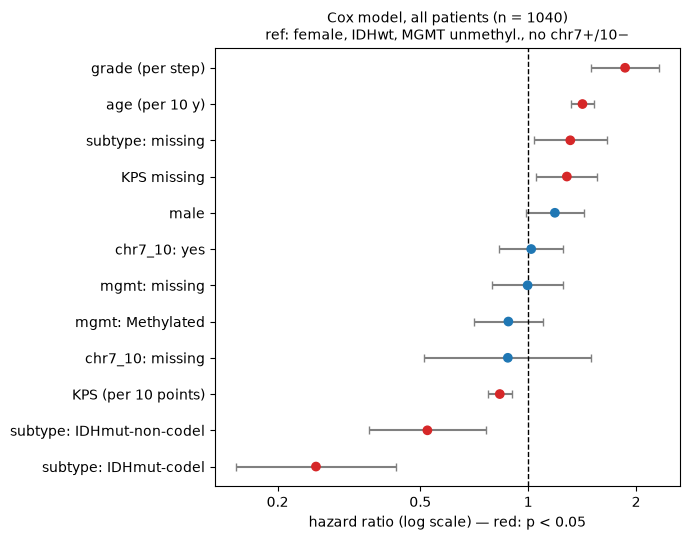

In [3]:
order = hr.sort_values("HR").index
fig, ax = plt.subplots(figsize=(7, 5.5))
ypos = np.arange(len(order))
sig = hr.loc[order, "p"] < 0.05
ax.errorbar(hr.loc[order, "HR"], ypos,
            xerr=[hr.loc[order, "HR"] - hr.loc[order, "CI low"], hr.loc[order, "CI high"] - hr.loc[order, "HR"]],
            fmt="none", ecolor="gray", capsize=3)
ax.scatter(hr.loc[order, "HR"], ypos, c=np.where(sig, "C3", "C0"), zorder=3)
ax.axvline(1, ls="--", c="k", lw=1)
ax.set_xscale("log"); ax.set_yticks(ypos, order)
ax.set_xticks([0.2, 0.5, 1, 2], ["0.2", "0.5", "1", "2"]); ax.minorticks_off()
ax.set_xlabel("hazard ratio (log scale) — red: p < 0.05")
ax.set_title("Cox model, all patients (n = 1040)\nref: female, IDHwt, MGMT unmethyl., no chr7+/10−", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIG}/hazard_ratios.png", dpi=150)

## 2. Permutation importance (test set)
Shuffle one **original** feature in the test set (so all one-hot columns of `subtype` move together),
measure how much Uno's C drops. 30 shuffles per feature → mean ± std.
A drop near 0 means the model does not rely on that feature *given the others*.

Tree hyperparameters = what the inner CV picked on the full training set in Step 4.

In [4]:
def pipe(model):
    return Pipeline([("pre", make_preprocessor()), ("model", model)])

final = {
    "Cox – full": pipe(CoxPHSurvivalAnalysis(alpha=0.1)),
    "RSF": pipe(RandomSurvivalForest(n_estimators=300, max_features="sqrt", min_samples_leaf=15,
                                     random_state=SEED, n_jobs=-1)),
    "GBSA": pipe(GradientBoostingSurvivalAnalysis(learning_rate=0.1, max_depth=2, n_estimators=100,
                                                  subsample=0.8, random_state=SEED)),
}
for m in final.values():
    m.fit(X_train, y_train)

def uno(model, Xs):
    return concordance_index_ipcw(y_train, y_test, model.predict(Xs), tau=EVAL_TIMES.max())[0]

rng = np.random.default_rng(SEED)
imp = {}
for name, m in final.items():
    base = uno(m, X_test)
    drops = {}
    for col in X_test.columns:
        d = []
        for _ in range(30):
            Xp = X_test.copy()
            Xp[col] = rng.permutation(Xp[col].to_numpy())
            d.append(base - uno(m, Xp))
        drops[col] = (np.mean(d), np.std(d))
    imp[name] = drops

imp_mean = pd.DataFrame({n: {c: v[0] for c, v in d.items()} for n, d in imp.items()})
imp_std = pd.DataFrame({n: {c: v[1] for c, v in d.items()} for n, d in imp.items()})
imp_mean = imp_mean.sort_values("Cox – full", ascending=False)
imp_mean.round(4)

,Cox – full,RSF,GBSA
age,0.0647,0.0589,0.0773
subtype,0.0446,0.0081,0.0260
grade,0.0408,0.0507,0.0560
kps,0.0168,0.0162,0.0128
sex,0.0017,0.0021,0.0002
mgmt,-0.0002,0.0032,0.0026
chr7_10,-0.0021,0.0019,0.0025


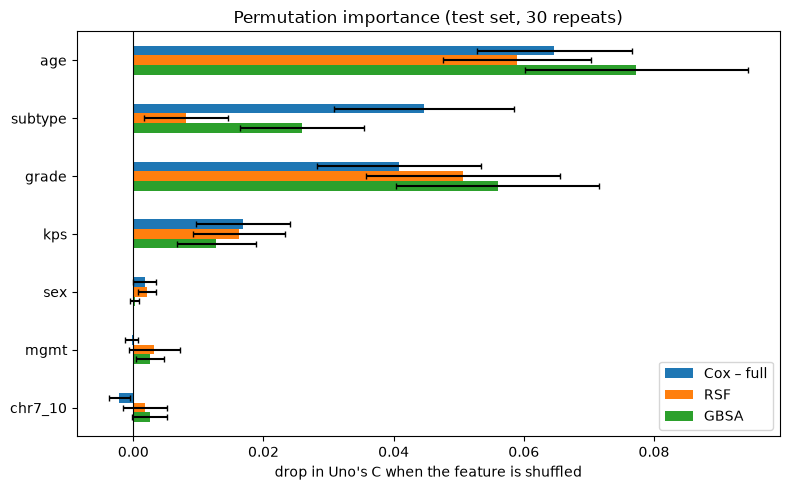

In [5]:
ax = imp_mean.plot.barh(xerr=imp_std.loc[imp_mean.index], figsize=(8, 5), capsize=2)
ax.invert_yaxis(); ax.axvline(0, c="k", lw=0.8)
ax.set_xlabel("drop in Uno's C when the feature is shuffled")
ax.set_title("Permutation importance (test set, 30 repeats)")
plt.tight_layout(); plt.savefig(f"{FIG}/permutation_importance.png", dpi=150)

## 3. Individual predictions
Three test patients: the lowest, median and highest predicted risk. The model gives a full survival curve per patient,
from which median survival and S(1y), S(2y) are read off.

,age,kps,grade,sex,subtype,mgmt,chr7_10,pred S(12m),pred S(24m),pred median (m),observed
patient,,,,,,,,,,,
lowest risk,20.0,NaN,2.0,Female,IDHmut-codel,Methylated,no,0.99,0.97,NaN,censored at 0.1 m
median risk,51.0,100.0,4.0,Male,IDHwt,Methylated,yes,0.76,0.42,21.0,died at 5.9 m
highest risk,89.0,60.0,4.0,Male,IDHwt,Unmethylated,yes,0.12,0.00,5.0,died at 0.9 m


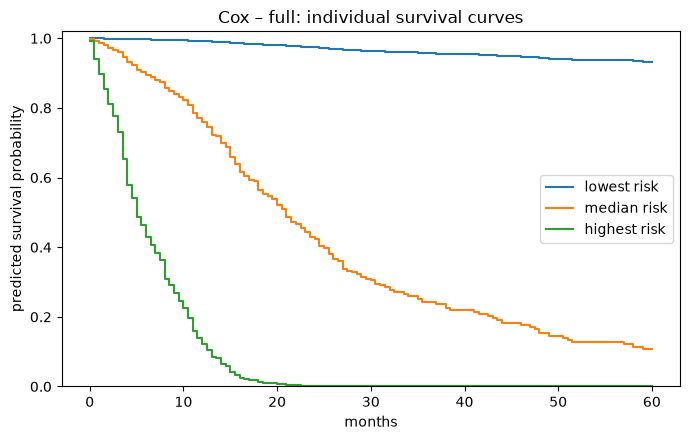

In [6]:
cox = final["Cox – full"]
risk = cox.predict(X_test)
picks = {"lowest risk": np.argmin(risk), "median risk": np.argsort(risk)[len(risk) // 2], "highest risk": np.argmax(risk)}

grid = np.linspace(0, 60, 121)
fig, ax = plt.subplots(figsize=(7, 4.5))
rows = []
for label, i in picks.items():
    s = survival_at(cox, X_test.iloc[[i]], grid)[0]
    ax.step(grid, s, where="post", label=label)
    med = grid[np.argmax(s <= 0.5)] if (s <= 0.5).any() else np.nan
    rows.append({"patient": label, **X_test.iloc[i].to_dict(),
                 "pred S(12m)": s[np.searchsorted(grid, 12)], "pred S(24m)": s[np.searchsorted(grid, 24)],
                 "pred median (m)": med,
                 "observed": f"{'died' if y_test['event'][i] else 'censored'} at {y_test['time'][i]:.1f} m"})
ax.set(xlabel="months", ylabel="predicted survival probability", title="Cox – full: individual survival curves", ylim=(0, 1.02))
ax.legend(); plt.tight_layout(); plt.savefig(f"{FIG}/individual_curves.png", dpi=150)
pd.DataFrame(rows).set_index("patient").round(2)

## 4. Figures for the report (re-drawn from earlier steps)

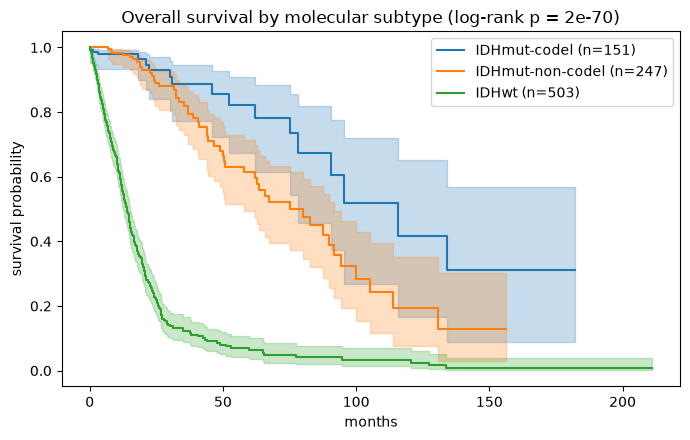

In [7]:
df = pd.read_csv("../data/processed/glioma.csv").dropna(subset=["subtype"])
fig, ax = plt.subplots(figsize=(7, 4.5))
for g, sub in df.groupby("subtype"):
    KaplanMeierFitter().fit(sub["time"], sub["event"], label=f"{g} (n={len(sub)})").plot_survival_function(ax=ax)
p = multivariate_logrank_test(df["time"], df["subtype"], df["event"]).p_value
ax.set(xlabel="months", ylabel="survival probability", title=f"Overall survival by molecular subtype (log-rank p = {p:.0e})")
plt.tight_layout(); plt.savefig(f"{FIG}/km_subtype.png", dpi=150)

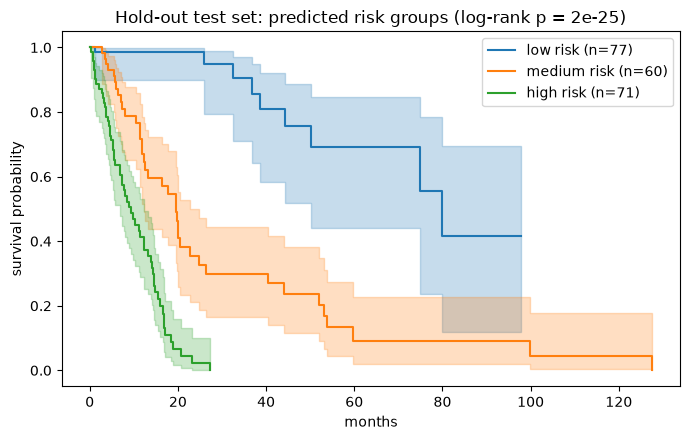

In [8]:
risk_te = cox.predict(X_test)
cuts = np.quantile(cox.predict(X_train), [1/3, 2/3])
group = pd.Series(np.digitize(risk_te, cuts)).map({0: "low", 1: "medium", 2: "high"})
fig, ax = plt.subplots(figsize=(7, 4.5))
for g in ["low", "medium", "high"]:
    m = (group == g).to_numpy()
    KaplanMeierFitter().fit(y_test["time"][m], y_test["event"][m], label=f"{g} risk (n={m.sum()})").plot_survival_function(ax=ax)
p = multivariate_logrank_test(y_test["time"], group, y_test["event"]).p_value
ax.set(xlabel="months", ylabel="survival probability", title=f"Hold-out test set: predicted risk groups (log-rank p = {p:.0e})")
plt.tight_layout(); plt.savefig(f"{FIG}/test_risk_groups.png", dpi=150)

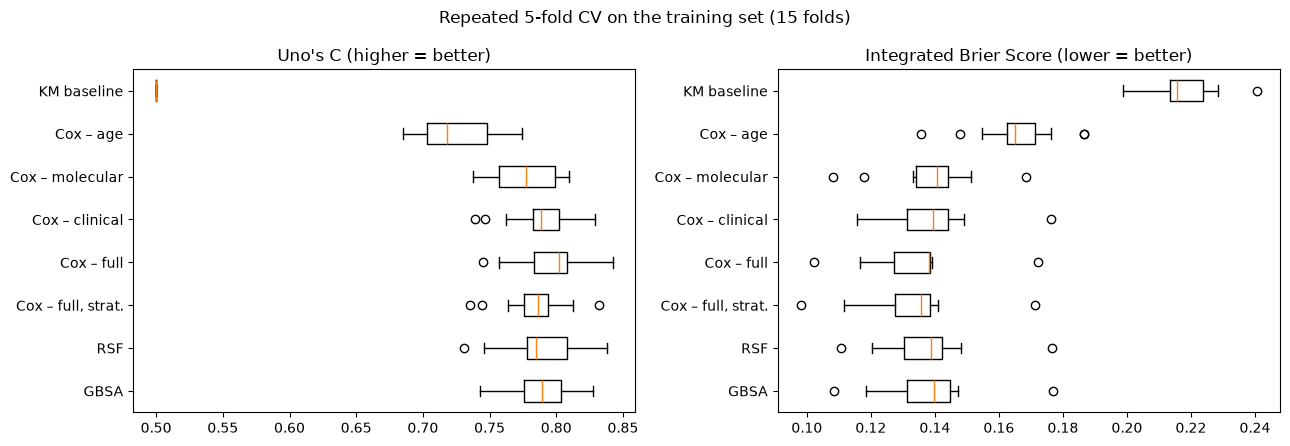

In [9]:
cv = pd.concat([pd.read_csv("../results/cv_step3.csv"), pd.read_csv("../results/cv_step4.csv").drop(columns="params")])
order = ["KM baseline", "Cox – age", "Cox – molecular", "Cox – clinical", "Cox – full", "Cox – full, strat.", "RSF", "GBSA"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, metric, title in [(ax[0], "uno_c", "Uno's C (higher = better)"), (ax[1], "ibs", "Integrated Brier Score (lower = better)")]:
    a.boxplot([cv.loc[cv.model == n, metric] for n in order], vert=False, tick_labels=order)
    a.invert_yaxis(); a.set_title(title)
fig.suptitle("Repeated 5-fold CV on the training set (15 folds)")
plt.tight_layout(); plt.savefig(f"{FIG}/cv_comparison.png", dpi=150)

## Summary

**Hazard ratios (all 1040 patients):**
* **IDH-mutant + 1p/19q-codeleted: HR 0.26** vs IDHwt (≈ 4× lower hazard); IDH-mutant non-codel HR 0.52.
* **Grade: HR 1.86 per step**, even after adjusting for IDH status.
* **Age: HR 1.42 per 10 years**; **KPS: HR 0.83 per 10 points**.
* MGMT methylation (HR 0.88, p = 0.26) and chr7+/10− (HR 1.02) add nothing once IDH/grade/age are known.
  MGMT is known to be predictive of temozolomide **response** in GBM. Treatment is not in this data, so its
  prognostic signal is absorbed by IDH (most IDH-mutant tumours are also MGMT-methylated).
* **"Missing" is informative:** missing subtype (HR 1.31) and missing KPS (HR 1.28) both mean worse survival,
  which is likely related to which centres/cases had full molecular work-up. Dropping these patients (complete-case,
  Step 2) would have biased the cohort.

**Permutation importance:** all three models agree on the top 4: **age > grade ≈ subtype > KPS**; sex, MGMT and
chr7/10 contribute ~0. RSF relies much less on subtype and more on grade. Grade and IDH are strongly correlated
(almost all IDHwt are grade 4), so a model can use either one; permutation importance splits credit between
correlated features and must be read with that in mind.

**Individual curves:** the model separates patients well (S(24m) 0.97 vs 0.00 at the extremes). Note the lowest-risk
test patient was censored at 0.1 months, so their "observed" outcome says nothing. This is a reminder that single
patients cannot validate a survival model; only cohort-level metrics (Steps 3–4) can.